# Análisis del desempeño logístico y la satisfacción del cliente en Olist

## Proyecto — Módulo I
Diplomado en Métodos Estadísticos y Matemáticos para la Ciencia de Datos


## Contexto
El comercio electrónico representa un modelo de negoico en el que la satisfacción del cliente depende tanto de las características de los productos como de la calidad del servicio logístico

Olist proporciona un conjunto de datos comerciales reales que comprenden aproximadamente 100,000 pedidos realizados en Brasil entre los años 2016 y 2018, incluyendo información sobre productos, vendedores, precios, costos de envío, tiempos de entrega y evaluaciones de los clientes,

La división regional de Brasil, la participación de diferentes vendedores y distintas etapas del proceso de entrega permiten explorar cómo las condiciones logísticas se relacionan con la experiencia de compra.


## Planteamiento del problema
El cumplimiento de las fechas estimadas de entrega constituye un indicador relevante del desempeño logístico en el comercio electrónico. Sin embargo, entregar un pedido a tiempo no necesariamente garantiza una evaluación positiva por parte del consumidor.

Para esto, resulta necesario analizar otro factores, como las diferencias regionales, los costos de envío, el valor económico de los pedidos y la participación de vendedores múltiples, con la finalidad de identificar patrones asociados con la satisfacción del consumidor y posibles oportunidades de mejora operativa.

## Pregunta de investigación
¿Cómo se relacionan el cumplimiento de los tiempos de entrega, las diferencias logísticas por región y la participación de distintos vendedores con la satisfacción de los clientes así como el valor económico de los pedidos?

## Objetivo
Analizar la relación entre el desempeño logístico y la satisfacción de los clientes, considerando las características regionales, operativas y económicas de los pedidos, utilizando técnicas de análsis exploratorio, visualización y estadística.

Buscaremos:
* Evaluar el cumplimiento de los tiempos estimados de entrega.
* Comparar las calificaciones y el valor económico de los pedidos puntuales y tardíos.
* Identificar diferencias logísticas entre las regiones de Brasil.
* Examinar la asociación entre las etapas del proceso logístico y las evaluaciones de los consumidores.

**Unidad de observación:** El pedido entregado y evaluado, identificado mediante "order_id".

Aunque se integra información a nivel de artículo, los datos se agregan posteriormente a nivel de pedido para analizar el desempeño logístico, el valor económico y la satisfacción del cliente, evitando duplicidades que puedan distorsionar los resultados estadísticos.

## Procedencia de los datos

Fuente: Brazilian E-Commerce Public Dataset by Olist.

Repositorio:
https://github.com/olist/work-at-olist-data

Commit de origen:
d9e49802f3e92d09ee94ab9ccc5e457f207a8959

Periodo de referencia: 2016-2018.

Los archivos originales se conservan en data/raw/ sin
modificaciones. Las transformaciones se realizan mediante
Python, utilizando principalmente Pandas y NumPy.

### Reprodudibilidad y carga de las librerías

In [1]:
from pathlib import Path
from importlib.metadata import version
import sys
import os
import platform

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Configuración visual
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
sns.set_theme(style="whitegrid")

# Identificar la raíz del proyecto
ROOT = Path.cwd().resolve()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA_RAW = ROOT / "data" / "raw"
DATA_PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "figures"

# Información del entorno
def informacion_entorno():
    paquetes = [
        "pandas", "numpy", "matplotlib",
        "seaborn", "scipy", "ipykernel"
    ]

    print("Python:", platform.python_version())

    for paquete in paquetes:
        print(f"{paquete}: {version(paquete)}")

# Verificación inicial
print("=== INFORMACIÓN DEL ENTORNO ===")
informacion_entorno()

print("\n=== CONFIGURACIÓN DEL PROYECTO ===")
print("Intérprete:", sys.executable)
print("Proyecto:", ROOT)
print("Datos disponibles:", DATA_RAW.exists())

=== INFORMACIÓN DEL ENTORNO ===
Python: 3.15.1
pandas: 3.1.1
numpy: 2.5.5
matplotlib: 3.11.2
seaborn: 0.13.2
scipy: 1.18.1
ipykernel: 7.4.0

=== CONFIGURACIÓN DEL PROYECTO ===
Intérprete: /Users/gerardobalderas/Documents/VS CODE/MEMCD-Mod1-Proyecto/projmod1/bin/python
Proyecto: /Users/gerardobalderas/Documents/VS CODE/MEMCD-Mod1-Proyecto
Datos disponibles: True


### Obtención automática de los datos

Para garantizar la reproducibilidad del análisis, se implementa
una función que descarga los archivos CSV desde una versión
específica del repositorio original de Olist.

Los archivos se descargan únicamente cuando no existen en
data/raw/, conservando los datos originales sin modificaciones.

In [2]:
from urllib.request import urlretrieve

COMMIT_OLIST = "d9e49802f3e92d09ee94ab9ccc5e457f207a8959"

URL_BASE = (
    "https://raw.githubusercontent.com/olist/work-at-olist-data/"
    f"{COMMIT_OLIST}/datasets/"
)

ARCHIVOS = [
    "olist_orders_dataset.csv",
    "olist_order_items_dataset.csv",
    "olist_products_dataset.csv",
    "product_category_name_translation.csv",
    "olist_order_reviews_dataset.csv",
    "olist_customers_dataset.csv"
]


def descargar_csv(ruta):
    ruta.mkdir(parents=True, exist_ok=True)

    for archivo in ARCHIVOS:
        destino = ruta / archivo

        if not destino.is_file():
            print(f"Descargando: {archivo}")

            temporal = destino.with_suffix(".tmp")
            urlretrieve(URL_BASE + archivo, temporal)
            temporal.replace(destino)

        else:
            print(f"Disponible: {archivo}")


descargar_csv(DATA_RAW)

Disponible: olist_orders_dataset.csv
Disponible: olist_order_items_dataset.csv
Disponible: olist_products_dataset.csv
Disponible: product_category_name_translation.csv
Disponible: olist_order_reviews_dataset.csv
Disponible: olist_customers_dataset.csv


### Carga inicial de los datos

In [3]:
#Carga de los archivos CSV usando una función
def cargar_csv(ruta):
    tablas = {}

    for archivo in sorted(ruta.glob("*.csv")):
        if archivo.stem == "olist_geolocation_dataset": #este se brinca porque pesa demasiado y para el análsiis no creo que lo usemos
            continue

        tablas[archivo.stem] = pd.read_csv(archivo)

    return tablas


tablas = cargar_csv(DATA_RAW)

# Esto muestra la cantidad de filas y columnas de cada tabla
for nombre, df in tablas.items():
    print(f"{nombre}: {df.shape[0]:,} filas × {df.shape[1]} columnas")

# Vamos a validar que esté cargado todo y agregamos indicadores a las tablas
orders = tablas["olist_orders_dataset"]
items = tablas["olist_order_items_dataset"]
products = tablas["olist_products_dataset"]
categories = tablas["product_category_name_translation"]
reviews = tablas["olist_order_reviews_dataset"]
customers = tablas["olist_customers_dataset"]


olist_customers_dataset: 99,441 filas × 5 columnas
olist_order_items_dataset: 112,650 filas × 7 columnas
olist_order_payments_dataset: 103,886 filas × 5 columnas
olist_order_reviews_dataset: 99,224 filas × 7 columnas
olist_orders_dataset: 99,441 filas × 8 columnas
olist_products_dataset: 32,951 filas × 9 columnas
olist_sellers_dataset: 3,095 filas × 4 columnas
product_category_name_translation: 71 filas × 2 columnas


# Calidad de datos, limpieza y transformaciones
Antes de construir indicadores descriptivos, vamos a revisar los datasets para identificar valores faltantes, duplicados e inconsistencias.

In [4]:
# 2.1 Revisión de calidad de datos
print("=== 1. ESTATUS DE PEDIDOS Y FECHAS FALTANTES ===")
print(orders['order_status'].value_counts(dropna=False))
print("\nDatos faltantes por columna en orders:")
print(orders.isna().sum())

entregados_sin_fecha = orders[
    (orders['order_status'] == 'delivered') &
    (orders['order_delivered_customer_date'].isna())
]
print(f"\nPedidos marcados como 'delivered' pero sin fecha de entrega: {len(entregados_sin_fecha)}")

print("\n=== 2. RESEÑAS REPETIDAS POR PEDIDO ===")
total_reviews = len(reviews)
ordenes_unicas_rev = reviews['order_id'].nunique()
print(f"Total de filas en reviews: {total_reviews:,} | Pedidos únicos: {ordenes_unicas_rev:,}")
print(f"Pedidos con más de una reseña: {total_reviews - ordenes_unicas_rev:,}")
frecuencia_reviews = reviews["order_id"].value_counts()

pedidos_multiples = (frecuencia_reviews > 1).sum()
resenas_adicionales = total_reviews - ordenes_unicas_rev

print(f"Pedidos con múltiples reseñas: {pedidos_multiples:,}")
print(f"Reseñas adicionales: {resenas_adicionales:,}")

print("\n=== 3. PRODUCTOS SIN CATEGORÍA Y TRADUCCIONES FALTANTES ===")
print(f"Productos sin categoría (NA): {products['product_category_name'].isna().sum():,}")
cats_en_productos = set(products['product_category_name'].dropna().unique())
cats_en_traduccion = set(categories['product_category_name'].unique())
cats_faltantes = cats_en_productos - cats_en_traduccion
print(f"Categorías sin traducción en categories: {cats_faltantes}")

items_prod_diag = items.merge(products[['product_id', 'product_category_name']], on='product_id', how='left')
print(f"Artículos vendidos sin categoría (NA): {items_prod_diag['product_category_name'].isna().sum():,}")
print(f"Artículos en las 2 categorías sin traducción: {items_prod_diag['product_category_name'].isin(cats_faltantes).sum():,}")
print(f"Precio máximo de un artículo: R$ {items['price'].max():,.2f}")

=== 1. ESTATUS DE PEDIDOS Y FECHAS FALTANTES ===
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Datos faltantes por columna en orders:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Pedidos marcados como 'delivered' pero sin fecha de entrega: 8

=== 2. RESEÑAS REPETIDAS POR PEDIDO ===
Total de filas en reviews: 99,224 | Pedidos únicos: 98,673
Pedidos con más de una reseña: 551
Pedidos con múltiples reseñas: 547
Reseñas adicionales: 551

=== 3. PRODUCTOS SIN CATEGORÍA Y TRADUCCIONES FALTANTES ===
Productos sin categoría (NA): 610
Categorías sin traducción en cate

### Decisiones de limpieza y transformación

A partir de la revisión anterior, tomamos **cinco decisiones**:

1. **Pedidos sin fecha de entrega (`NA`) en `orders`:**
   * *Problema:* Hay **2,965 pedidos** sin fecha de entrega al cliente (`order_delivered_customer_date`).
   * *Qué hicimos y por qué:* Al revisar su estatus, **2,957** son pedidos cancelados (`canceled`: 625), en camino (`shipped`: 1,107), no disponibles (`unavailable`: 609) o aún en proceso. No son errores de captura: simplemente no tienen fecha porque nunca se entregaron. Rellenar esas fechas con el promedio o la mediana sería inventar entregas ficticias. Los otros **8 pedidos** sí aparecen como `delivered` pero no tienen fecha registrada.
   * *Consecuencia:* Nos quedamos solo con los pedidos realmente entregados (`delivered`) que tienen sus fechas completas (**96,470 órdenes**; **95,824** al cruzarlas con reseñas).

2. **Reseñas repetidas para un mismo pedido (`order_id`):**
   * *Problema:* La tabla `reviews` tiene 99,224 filas para 98,673 pedidos únicos; es decir, **551 pedidos** tienen más de una reseña.
   * *Qué hicimos y por qué:* Si cruzáramos las tablas directamente, esos pedidos se repetirían y contaríamos dos veces el dinero de sus productos. Ordenamos por fecha (`review_creation_date`) y nos quedamos solo con la última reseña de cada pedido.
   * *Consecuencia:* Evitamos duplicar **643 filas de artículos** y que las ventas totales salieran infladas por **R$ 58,338.48**.

3. **Productos sin categoría (`NA`) y nombres sin traducir:**
   * *Problema:* En `products` hay **610 productos sin categoría**, que equivalen a **1,603 artículos vendidos**. Además, la tabla de traducciones (`categories`) no trae dos categorías que sí existen en los productos: `pc_gamer` y `portateis_cozinha_e_preparadores_de_alimentos` (**24 artículos vendidos**).
   * *Qué hicimos y por qué:* En lugar de hacer un `inner join` (que los eliminaría) o borrar los `NA`, usamos un `left join`, etiquetamos los faltantes como `'sin_categoria'` y agregamos a mano la traducción de esas dos categorías.
   * *Consecuencia:* No perdimos **1,547 artículos ya entregados** ni dejamos fuera **R$ 174,892.94** de las ventas reales registradas de Olist.

4. **Valores extremos en precios y tiempos de entrega:**
   * *Problema:* Hay artículos de hasta **R$ 6,735.00** y entregas que tardaron hasta **208.35 días** (con retrasos de hasta **+188 días**; **4,881 pedidos** superan el límite de Tukey de 29.02 días).
   * *Qué hicimos y por qué:* Un dato extremo no siempre es un error de captura. Un envío que tardó 150 días es una falla real de paquetería y explica por qué el cliente calificó con 1 estrella. Para que estos casos extremos no jalen los resultados, usamos la **mediana** y el **rango intercuartílico (IQR)** en lugar de guiarnos solo por el promedio.
   * *Consecuencia:* Conservamos la experiencia real de los clientes más inconformes sin distorsionar las métricas típicas de entrega y precio.

5. **Fechas en desorden entre compra, paquetería y entrega:**
   * *Problema:* Dentro de los 95,824 pedidos entregados y evaluados, hay **188 registros** donde las fechas intermedias no siguen un orden lógico: 1 no tiene fecha de entrega a paquetería, 164 dicen que llegaron a paquetería *antes* de comprarse y 23 dicen que llegaron al cliente *antes* de salir a paquetería.
   * *Qué hicimos y por qué:* Si restáramos esas fechas tal cual, obtendríamos días negativos. Los conservamos para calcular el tiempo total (compra a entrega), pero los filtramos cuando analizamos por separado cuánto tarda el vendedor frente a la paquetería.
   * *Consecuencia:* Trabajamos con **95,636 pedidos** con fechas consistentes en las correlaciones por etapa sin alterar el total de ventas.

In [5]:
# 2.2 Limpieza y armado de la base final

# 1. Filtrar pedidos entregados con fechas completas y convertir a formato fecha
orders_clean = orders[orders['order_status'] == 'delivered'].dropna(
    subset=['order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date']
).copy()

cols_fecha = [
    'order_purchase_timestamp', 'order_approved_at',
    'order_delivered_carrier_date', 'order_delivered_customer_date',
    'order_estimated_delivery_date'
]
for col in cols_fecha:
    orders_clean[col] = pd.to_datetime(orders_clean[col])

# Calcular días reales de entrega y días de retraso (> 0 significa entrega tardía)
orders_clean['tiempo_entrega_dias'] = (
    orders_clean['order_delivered_customer_date'] - orders_clean['order_purchase_timestamp']
).dt.total_seconds() / 86400.0

orders_clean['retraso_dias'] = (
    orders_clean['order_delivered_customer_date'].dt.normalize() -
    orders_clean['order_estimated_delivery_date'].dt.normalize()
).dt.days

orders_clean['entrega_tardia'] = orders_clean['retraso_dias'] > 0

# Agrupar el cumplimiento en tramos de días
bins_retraso = [-np.inf, -7, 0, 3, 7, np.inf]
labels_retraso = [
    'Anticipado (>7d antes)', 'A tiempo (0 a 7d antes)',
    'Retraso leve (1-3d)', 'Retraso moderado (4-7d)', 'Retraso crítico (>7d)'
]
orders_clean['rango_cumplimiento'] = pd.cut(
    orders_clean['retraso_dias'], bins=bins_retraso, labels=labels_retraso
)

# 2. Quedarnos con la última reseña de cada pedido
reviews_clean = reviews.copy()
reviews_clean['review_creation_date_dt'] = pd.to_datetime(reviews_clean['review_creation_date'])
reviews_dedup = (
    reviews_clean.sort_values('review_creation_date_dt')
    .groupby('order_id', as_index=False)
    .last()
)

# 3. Unir productos con traducciones sin perder faltantes
products_clean = products.merge(categories, on='product_category_name', how='left')
mapa_faltantes = {
    'pc_gamer': 'pc_gamer',
    'portateis_cozinha_e_preparadores_de_alimentos': 'portable_kitchen_food_processors'
}
products_clean['category_en'] = (
    products_clean['product_category_name_english']
    .fillna(products_clean['product_category_name'].map(mapa_faltantes))
    .fillna('sin_categoria')
)
products_clean['category_pt'] = products_clean['product_category_name'].fillna('sin_categoria')

# 4. Unir todas las tablas limpias a nivel artículo entregado y evaluado
df_analisis = (
    items
    .merge(products_clean[['product_id', 'category_pt', 'category_en', 'product_weight_g']], on='product_id', how='left')
    .merge(orders_clean, on='order_id', how='inner')
    .merge(reviews_dedup[['order_id', 'review_score']], on='order_id', how='inner')
)
df_analisis['valor_total_item'] = df_analisis['price'] + df_analisis['freight_value']

# Guardar base limpia
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
df_analisis.to_csv(DATA_PROCESSED / "olist_items_entregados_limpio.csv", index=False)

# --- Comprobación del efecto de la limpieza ---
pedidos_eval = orders_clean.merge(reviews_dedup[['order_id', 'review_score']], on='order_id', how='inner')

na_carrier = pedidos_eval['order_delivered_carrier_date'].isna().sum()
anom_carrier = (pedidos_eval['order_delivered_carrier_date'] < pedidos_eval['order_purchase_timestamp']).sum()
anom_cust = (pedidos_eval['order_delivered_customer_date'] < pedidos_eval['order_delivered_carrier_date']).sum()
total_anom_crono = (
    pedidos_eval['order_delivered_carrier_date'].isna() |
    (pedidos_eval['order_delivered_carrier_date'] < pedidos_eval['order_purchase_timestamp']) |
    (pedidos_eval['order_delivered_customer_date'] < pedidos_eval['order_delivered_carrier_date'])
).sum()

q1_ent, q3_ent = np.percentile(pedidos_eval['tiempo_entrega_dias'], [25, 75])
iqr_ent = q3_ent - q1_ent
umbral_tukey = q3_ent + 1.5 * iqr_ent
n_outliers_ent = (pedidos_eval['tiempo_entrega_dias'] > umbral_tukey).sum()

df_sin_dedup = items.merge(orders_clean[['order_id']], on='order_id').merge(reviews[['order_id']], on='order_id')
prod_inner = products.merge(categories, on='product_category_name', how='inner')
df_cat_inner = df_analisis[df_analisis['product_id'].isin(prod_inner['product_id'])]

print("=== EFECTO DE LA LIMPIEZA EN LOS DATOS ===")
print(f"Ventas infladas evitadas al quitar reseñas repetidas: R$ {df_sin_dedup['price'].sum() - df_analisis['price'].sum():,.2f} ({len(df_sin_dedup) - len(df_analisis):,} filas)")
print(f"Ventas rescatadas con left join en categorías:        R$ {df_analisis['price'].sum() - df_cat_inner['price'].sum():,.2f} ({len(df_analisis) - len(df_cat_inner):,} artículos)")
print(f"Fechas en desorden entre etapas: {total_anom_crono} pedidos (sin paquetería: {na_carrier}, despacho < compra: {anom_carrier}, entrega < despacho: {anom_cust})")
print(f"Atípicos en tiempo de entrega (> {umbral_tukey:.2f}d): {n_outliers_ent:,} ({n_outliers_ent/len(pedidos_eval)*100:.2f}%) | Máx entrega: {pedidos_eval['tiempo_entrega_dias'].max():.2f}d | Máx retraso: +{pedidos_eval['retraso_dias'].max()}d")

print("\n=== RESUMEN DE LA BASE LIMPIA ===")
print(f"Artículos entregados y evaluados: {len(df_analisis):,}")
print(f"Pedidos únicos representados:     {df_analisis['order_id'].nunique():,}")
print(f"Ventas totales de producto:       R$ {df_analisis['price'].sum():,.2f}")
print(f"Ventas totales con flete (GMV):   R$ {df_analisis['valor_total_item'].sum():,.2f}")

=== EFECTO DE LA LIMPIEZA EN LOS DATOS ===
Ventas infladas evitadas al quitar reseñas repetidas: R$ 58,338.48 (643 filas)
Ventas rescatadas con left join en categorías:        R$ 174,892.94 (1,547 artículos)
Fechas en desorden entre etapas: 188 pedidos (sin paquetería: 1, despacho < compra: 164, entrega < despacho: 23)
Atípicos en tiempo de entrega (> 29.02d): 4,881 (5.09%) | Máx entrega: 208.35d | Máx retraso: +188d

=== RESUMEN DE LA BASE LIMPIA ===
Artículos entregados y evaluados: 109,362
Pedidos únicos representados:     95,824
Ventas totales de producto:       R$ 13,108,744.45
Ventas totales con flete (GMV):   R$ 15,294,664.29


In [6]:
#Estadistica
def resumen(df, grupo_col, var_col):
    """Recibe una base de datos,
    el nombre de la columna que permite separar los datos en categorías y
    el nombre de la columna que se desea analizar.
    Regresa una agrupación por categoría junto con el número de datos de cada una,
    la media, la desviación estándar, la mediana, los percentiles 25, 75 y 90,
    y el rango intercuartílico. """

    def calc_metricas(x):
        q25, med, q75, p90 = np.percentile(x, [25, 50, 75, 90])
        return pd.Series({
            'n': len(x),
            'media': x.mean(),
            'std': x.std(),
            'mediana': med,
            'P25': q25,
            'P75': q75,
            'IQR': q75 - q25,
            'P90': p90
        })
    return df.groupby(grupo_col, observed=False)[var_col].apply(calc_metricas).unstack()

# Unimos la información de orders_clean con reviews_clean para tener acceso al score
orders_clean_score = orders_clean.merge(
    reviews_dedup[['order_id', 'review_score']],
    on='order_id',
    how='left'
)

# Sumamos el valor total por cada orden para no duplicar filas al unir
valor_por_orden = (
    df_analisis.groupby('order_id')['valor_total_item']
    .sum()
    .reset_index()
)

# Unimos el valor total a orders_clean_score
orders_clean_score_v = orders_clean_score.merge(
    valor_por_orden,
    on='order_id',
    how='left'
)

#Dejamos unicamente las ordenes que cuenten co  una calificación

orders_clean_score__v_l = orders_clean_score_v.dropna(subset=['review_score'])

#Comparación a nivel pedido: Puntuales vs. Tardíos (Tiempo de entrega y Calificación)
print("Tiempo entrega (días): puntuales vs tardíos")
display(resumen(orders_clean_score__v_l, 'entrega_tardia', 'tiempo_entrega_dias').round(2))

print("Calificación (review score): puntuales vs. tardíos")
display(resumen(orders_clean_score__v_l, 'entrega_tardia', 'review_score').round(2))

print("Precio del pedido: puntuales vs. tardíos")
display(resumen(orders_clean_score__v_l, 'entrega_tardia', 'valor_total_item').round(2))



Tiempo entrega (días): puntuales vs tardíos


,n,media,std,mediana,P25,P75,IQR,P90
entrega_tardia,,,,,,,,
False,89443.0,11.00,6.31,9.80,6.39,14.28,7.89,19.69
True,6381.0,33.82,17.31,31.18,24.50,39.91,15.40,49.80


Calificación (review score): puntuales vs. tardíos


,n,media,std,mediana,P25,P75,IQR,P90
entrega_tardia,,,,,,,,
False,89443.0,4.29,1.15,5.0,4.0,5.0,1.0,5.0
True,6381.0,2.27,1.57,1.0,1.0,4.0,3.0,5.0


Precio del pedido: puntuales vs. tardíos


,n,media,std,mediana,P25,P75,IQR,P90
entrega_tardia,,,,,,,,
False,89443.0,158.54,216.81,104.59,61.58,175.32,113.74,302.76
True,6381.0,174.61,226.75,113.33,67.50,189.56,122.06,335.58


### Interpretación de resultados: análisis de entregas, satisfacción y categorías

Los resultados muestran tres hallazgos importantes sobre el comportamiento de las entregas, la satisfacción de los clientes y el valor económico de las categorías de productos.

Primero, la mediana confirma esta diferencia: el 50% de los pedidos puntuales se entregó en 9.80 días o menos, mientras que en los tardíos fue de 31.18 días o menos, y la desviación estándar de los pedidos tardíos 17.31 indica una mayor variabilidad en sus tiempos de entrega, por lo que los pedidos tardíos no solamente incumplen la fecha estimada, sino que presentan tiempos de entrega considerablemente mayores y menos consistentes.

Segundo, los pedidos entregados puntualmente obtuvieron una calificación promedio de 4.29 sobre 5, lo que refleja un nivel de satisfacción relativamente alto, por el contrario, los pedidos tardíos obtuvieron un promedio de apenas 2.27 sobre 5, adicional, en los pedidos tardíos, la mediana es 1, lo que evidencia una fuerte concentración de calificaciones negativas, por lo que existe una asociación importante entre los retrasos en las entregas y una menor satisfacción del cliente. Los pedidos tardíos reciben calificaciones considerablemente inferiores a los pedidos puntuales.

Por último, los pedidos tardíos presentan precios ligeramente superiores a los puntuales, tanto en promedio como en mediana. Además, muestran una dispersión algo mayor en sus valores. Esto podría sugerir que los pedidos de mayor valor tienen una mayor presencia entre las entregas tardías, aunque no es suficiente para afirmar que los pedidos más caros necesariamente se retrasan más.

In [7]:
# Verificamos si la distribución de los datos es normal o no


for var in ['review_score', 'tiempo_entrega_dias', 'valor_total_item']:

    datos = orders_clean_score__v_l[var].dropna()

    # Distribución normal de referencia
    normal = stats.norm(loc=datos.mean(), scale=datos.std())

    # Prueba de Kolmogorov-Smirnov
    ks_stat, p_val_norm = stats.kstest(
        datos.to_numpy(),
        normal.cdf
    )

    # Cálculo de asimetría
    asimetria = stats.skew(datos)

    print(f"Variable: {var}")
    print(f"  -> Estadístico KS = {ks_stat:.4f} | "
          f"p-value = {p_val_norm:.5e} | "
          f"Asimetría = {asimetria:.2f}")

Variable: review_score
  -> Estadístico KS = 0.3366 | p-value = 0.00000e+00 | Asimetría = -1.48
Variable: tiempo_entrega_dias
  -> Estadístico KS = 0.1305 | p-value = 0.00000e+00 | Asimetría = 3.78
Variable: valor_total_item
  -> Estadístico KS = 0.2564 | p-value = 0.00000e+00 | Asimetría = 9.24


El análisis de distribución mediante la prueba de Kolmogorov-Smirnov y el cálculo de la asimetría permitió identificar que ninguna de las tres variables analizadas sigue una distribución normal.
En primer lugar, la variable review_score presenta una asimetría negativa -1.48, lo que indica una concentración de calificaciones en los valores altos y una menor proporción de calificaciones bajas.
Por otra parte, tiempo_entrega_dias presenta una asimetría positiva 3.78, lo que refleja que la mayoría de los pedidos se entrega en periodos relativamente cortos, aunque existen algunos casos con tiempos de entrega considerablemente elevados.
Finalmente, valor_total_item presenta una asimetría positiva extrema 9.24, lo que indica una concentración de artículos con precios bajos o moderados y la presencia de algunos productos con valores considerablemente superiores.
En conjunto, estos resultados muestran que las variables presentan distribuciones asimétricas y se alejan de la normalidad.


In [8]:
# Separamos puntuales y tardíos
puntuales = orders_clean_score__v_l[orders_clean_score__v_l['entrega_tardia'] == False]
tardios = orders_clean_score__v_l[orders_clean_score__v_l['entrega_tardia'] == True]

# Prueba U de Mann-Whitney: Pedidos puntuales vs. Pedidos tardíos
for var in ['review_score', 'tiempo_entrega_dias', 'valor_total_item']:
  #Podemos utilizar la prueba U de Mann-Whitney derivado que las variables son de tipo ordinal
    u_stat, p_val = stats.mannwhitneyu(
        puntuales[var].dropna(),
        tardios[var].dropna(),
        alternative='two-sided'
    )
    print(f"Mann-Whitney U ({var}) -> U = {u_stat:,.2f} | p-value = {p_val:.5e}")



Mann-Whitney U (review_score) -> U = 467,371,957.00 | p-value = 0.00000e+00
Mann-Whitney U (tiempo_entrega_dias) -> U = 30,206,272.00 | p-value = 0.00000e+00
Mann-Whitney U (valor_total_item) -> U = 267,141,668.50 | p-value = 1.37166e-17


#### Prueba U de Mann-Whitney
Esta prueba nos permite comparar los pedidos puntuales y tardíos y su diferencia en las distribuciones de sus variables, las de interés son:

**1. Calificación del pedido(revier_score):** El p-value es prácticamente cero, por lo que existe evidencia estadística suficiente para rechazar la hipótesis nula de igualdad de distribuciones entre pedidos puntuales y tardíos. Esto significa que las calificaciones de los clientes presentan diferencias significativas dependiendo de si el pedido llegó a tiempo o presentó retrasos. Este resultado respalda lo observado anteriormente en el análisis descriptivo: los pedidos puntuales tienen una calificación promedio de 4.29, mientras que los tardíos tienen una media de 2.27.

**2. Tiempo de entrega (tiempo_entrega_dias):** El p-value también es prácticamente cero, lo que indica diferencias estadísticamente significativas en los tiempos de entrega entre ambos grupos. En otras palabras, el tiempo de entrega presenta diferencias claras entre los pedidos que cumplen y los que incumplen la fecha estimada.

**3. Valor total del artículo (valor_total_item):** El p-value de 1.37165e-17 es considerablemente inferior a 0.05. Por lo tanto, también se rechaza la hipótesis nula y se concluye que existen diferencias estadísticamente significativas en la distribución del valor de los artículos entre pedidos puntuales y tardíos.


In [9]:
# Correlación de Spearman
pares_correlacion = [('retraso_dias', 'review_score'),
    ('tiempo_entrega_dias', 'review_score'),
    ('valor_total_item', 'review_score'),
    ('retraso_dias', 'valor_total_item')]

resultados_spearman = []
for var_x, var_y in pares_correlacion:
    sub = orders_clean_score__v_l[[var_x, var_y]].dropna()
    rho, p_val = stats.spearmanr(sub[var_x], sub[var_y])
    resultados_spearman.append({
        'Variable X': var_x,
        'Variable Y': var_y,
        'Spearman_rho': round(rho, 4),
        'p_value': f"{p_val:.4e}"
    })

print("Correlaciones de Spearman")
display(pd.DataFrame(resultados_spearman))

# Prueba Chi-cuadrada de independencia (rango_cumplimiento vs. review_score)
tabla_contingencia = pd.crosstab(orders_clean_score__v_l['rango_cumplimiento'], orders_clean_score__v_l['review_score'])
chi2, p_chi2, dof, expected = stats.chi2_contingency(tabla_contingencia)

# Cálculo de V de Cramér
n_total = tabla_contingencia.sum().sum()
min_dim = min(tabla_contingencia.shape) - 1
v_cramer = np.sqrt(chi2 / (n_total * min_dim))

print(f"\nPrueba Chi-cuadrada (rango_cumplimiento vs. review_score):")
print(f"Chi2 = {chi2:,.2f} | gl = {dof} | p-value = {p_chi2:.4e} | V de Cramér = {v_cramer:.4f}")

Correlaciones de Spearman


,Variable X,Variable Y,Spearman_rho,p_value
0,retraso_dias,review_score,-0.1763,0.0000e+00
1,tiempo_entrega_dias,review_score,-0.2345,0.0000e+00
2,valor_total_item,review_score,-0.0390,1.5198e-33
3,retraso_dias,valor_total_item,-0.0609,2.2331e-79



Prueba Chi-cuadrada (rango_cumplimiento vs. review_score):
Chi2 = 19,735.11 | gl = 16 | p-value = 0.0000e+00 | V de Cramér = 0.2269


Los resultados del análisis de correlación de Spearman evidencian una relación negativa entre las variables relacionadas con el desempeño logístico y la calificación otorgada por los clientes. En particular, el tiempo de entrega presentó la mayor correlación negativa con el review_score ρ = -0.2345, seguido del retraso en días ρ = -0.1763. Estos resultados sugieren que, a medida que aumenta el tiempo requerido para entregar un pedido o se presentan mayores retrasos, las calificaciones de los clientes tienden a disminuir. Por otra parte, se identificó una correlación muy baja entre el valor total del artículo y la calificación de las reseñas ρ = -0.0390, así como la relación entre el retraso en días y el valor total del artículo fue muy débil ρ = -0.0609, lo que sugiere que el valor del pedido no tiene un impacto en los retrasos de entregas o en la calificación del pedido. En cuanto a la prueba Chi-cuadrada, se encontró una asociación estadísticamente significativa entre el rango de cumplimiento de las entregas y las calificaciones de los clientes. El coeficiente V de Cramér 0.2269 indica que dicha asociación presenta una intensidad moderada-baja. En conjunto, los resultados sugieren que el desempeño logístico, particularmente los tiempos de entrega y el cumplimiento de los plazos establecidos, está relacionado con la percepción de satisfacción de los clientes. Sin embargo, las magnitudes de las correlaciones indican que existen otros factores que también podrían intervenir en las calificaciones otorgadas.

In [10]:
#Análisis por región

# Consolidación validada a nivel de pedido único (order_id)
items_por_pedido = (items.groupby('order_id', as_index=False)
    .agg(precio_total=('price', 'sum'),
        flete_total=('freight_value', 'sum'),
        n_items=('order_item_id', 'count'),
        n_sellers=('seller_id', 'nunique')))

df_pedidos = (orders_clean_score_v.dropna(subset=['review_score'])
    .drop_duplicates(subset=['order_id'])
    .merge(items_por_pedido, on='order_id', how='inner', validate='one_to_one')
    .merge(customers[['customer_id', 'customer_state']], on='customer_id', how='left', validate='many_to_one')
    .copy())

# Indicadores auxiliares a nivel pedido
df_pedidos['negativa'] = df_pedidos['review_score'].isin([1, 2])
df_pedidos['tardia'] = df_pedidos['entrega_tardia'] == True

mapa_regiones = {
    'SP': 'Sureste', 'RJ': 'Sureste', 'MG': 'Sureste', 'ES': 'Sureste',
    'PR': 'Sur', 'RS': 'Sur', 'SC': 'Sur',
    'DF': 'Centro-Oeste', 'GO': 'Centro-Oeste', 'MS': 'Centro-Oeste', 'MT': 'Centro-Oeste',
    'BA': 'Noreste', 'PE': 'Noreste', 'CE': 'Noreste', 'RN': 'Noreste',
    'PB': 'Noreste', 'MA': 'Noreste', 'AL': 'Noreste', 'SE': 'Noreste', 'PI': 'Noreste',
    'PA': 'Norte', 'AM': 'Norte', 'RO': 'Norte', 'AC': 'Norte', 'AP': 'Norte', 'RR': 'Norte', 'TO': 'Norte'
}
df_pedidos['region'] = df_pedidos['customer_state'].map(mapa_regiones)

def calc_iqr(s):
    return np.percentile(s, 75) - np.percentile(s, 25)

# Dimensión Regional
sintesis_macroregion = (
    df_pedidos.groupby('region', dropna=False).agg(n_pedidos=('order_id', 'count'),
        mediana_entrega_dias=('tiempo_entrega_dias', 'median'),
        iqr_entrega_dias=('tiempo_entrega_dias', calc_iqr),
        tasa_retraso=('tardia', lambda x: x.mean() * 100),
        tasa_reviews_neg =('negativa', lambda x: x.mean() * 100),
        calificacion_promedio=('review_score', 'mean'),
        mediana_precio_brl=('precio_total', 'median'),
        valor_total_brl=('precio_total', 'sum')).sort_values('tasa_retraso', ascending=False))


print('\n Desepeño y valor por Macroregion')
display(sintesis_macroregion.round(2).reset_index())

sintesis_estado = (
    df_pedidos.groupby('customer_state', dropna=False).agg(n_pedidos=('order_id', 'count'),
        mediana_entrega_dias=('tiempo_entrega_dias', 'median'),
        iqr_entrega_dias=('tiempo_entrega_dias', calc_iqr),
        tasa_retraso=('tardia', lambda x: x.mean() * 100),
        tasa_reviews_neg=('negativa', lambda x: x.mean() * 100),
        calificacion_promedio=('review_score', 'mean'),
        mediana_precio_brl=('precio_total', 'median')).sort_values('tasa_retraso', ascending=False))

print('\n Los 10 Estados con mayores tasas de retrasos')
display(sintesis_estado.head(10).round(2).reset_index())


 Desepeño y valor por Macroregion


,region,n_pedidos,mediana_entrega_dias,iqr_entrega_dias,tasa_retraso,tasa_reviews_neg,calificacion_promedio,mediana_precio_brl,valor_total_brl
0,Noreste,8975,17.29,11.05,12.49,16.75,3.97,99.00,1485031.55
1,Norte,1779,20.15,12.76,8.32,15.18,4.03,105.00,323356.59
2,Centro-Oeste,5594,13.27,8.52,6.45,13.16,4.13,89.99,841043.64
3,Sureste,65731,8.69,7.33,6.01,12.38,4.18,82.40,8569839.86
4,Sur,13745,12.11,8.66,5.81,11.82,4.19,88.90,1889472.81



 Los 10 Estados con mayores tasas de retrasos


,customer_state,n_pedidos,mediana_entrega_dias,iqr_entrega_dias,tasa_retraso,tasa_reviews_neg,calificacion_promedio,mediana_precio_brl
0,AL,394,22.31,14.48,20.81,21.32,3.85,105.95
1,MA,712,19.13,10.18,17.13,19.94,3.83,98.00
2,SE,334,17.99,11.20,14.97,18.86,3.91,99.94
3,PI,471,16.31,10.14,13.80,16.14,3.99,109.90
4,CE,1273,18.17,11.39,13.67,17.12,3.94,99.90
5,RR,41,25.01,18.52,12.20,14.63,3.90,122.99
6,RJ,12211,12.03,10.25,11.92,18.30,3.97,89.99
7,BA,3229,16.89,10.70,11.89,17.00,3.93,93.00
8,PA,933,21.06,13.45,10.72,17.90,3.91,105.00
9,ES,1969,13.59,8.92,10.41,13.81,4.08,89.00


La ubicación geográfica constituye una dimensión relevante para comprender las diferencias en el desempeño de las entregas y la satisfacción de los clientes. Los resultados sugieren que las regiones con mayores tasas de retraso también presentan mayores porcentajes de reseñas negativas, aunque esta relación es descriptiva y no demuestra causalidad.

# Visualización Exploratoria e Interpretación de Hallazgos

  A partir de las tablas depuradas (`orders_clean`, `reviews_dedup`, `items` y `customers`), se consolida la base a nivel de **pedido único entregado y evaluado** ($n = 95,824$) para elaborar las visualizaciones gráficas que nos ayudarán a responder nuestras preguntas de investigación. Cada gráfico incluye su lectura técnica, el hallazgo operativo principal y sus limitaciones metodológicas.

In [11]:
# 4.0 Consolidación a nivel de pedido único (order_id)
FIGURES.mkdir(parents=True, exist_ok=True)

# Agregación de artículos y vendedores por pedido
items_por_pedido = (
    items.groupby("order_id", as_index=False)
    .agg(
        precio_total=("price", "sum"),
        flete_total=("freight_value", "sum"),
        n_items=("order_item_id", "count"),
        n_sellers=("seller_id", "nunique")
    )
)

# Partimos de la tabla del Paso 3 asegurándonos de que no haya reseñas duplicadas por order_id
df_pedidos = (
    orders_clean_score_v.dropna(subset=["review_score"])
    .drop_duplicates(subset=["order_id"])
    .merge(items_por_pedido, on="order_id", how="inner")
    .merge(customers[["customer_id", "customer_state"]], on="customer_id", how="left")
    .copy()
)

# Variables derivadas para descomposición logística y análisis regional
df_pedidos["tiempo_vendedor_dias"] = (
    df_pedidos["order_delivered_carrier_date"] - df_pedidos["order_purchase_timestamp"]
).dt.total_seconds() / 86400.0

df_pedidos["tiempo_transportista_dias"] = (
    df_pedidos["order_delivered_customer_date"] - df_pedidos["order_delivered_carrier_date"]
).dt.total_seconds() / 86400.0

df_pedidos["ratio_flete"] = df_pedidos["flete_total"] / df_pedidos["precio_total"]

mapa_regiones = {
    "SP": "Sureste", "RJ": "Sureste", "MG": "Sureste", "ES": "Sureste",
    "PR": "Sur", "RS": "Sur", "SC": "Sur",
    "DF": "Centro-Oeste", "GO": "Centro-Oeste", "MS": "Centro-Oeste", "MT": "Centro-Oeste",
    "BA": "Noreste", "PE": "Noreste", "CE": "Noreste", "RN": "Noreste",
    "PB": "Noreste", "MA": "Noreste", "AL": "Noreste", "SE": "Noreste", "PI": "Noreste",
    "PA": "Norte", "AM": "Norte", "RO": "Norte", "AC": "Norte", "AP": "Norte", "RR": "Norte", "TO": "Norte"
}
df_pedidos["region"] = df_pedidos["customer_state"].map(mapa_regiones)

# Paleta vibrante unificada para todas las visualizaciones
PALETA_VIBRANTE = ["#E63946", "#F77F00", "#FCBF49", "#0096C7", "#1D3557"]

print(f"Pedidos únicos evaluados listos para visualización: {len(df_pedidos):,}")

Pedidos únicos evaluados listos para visualización: 95,824


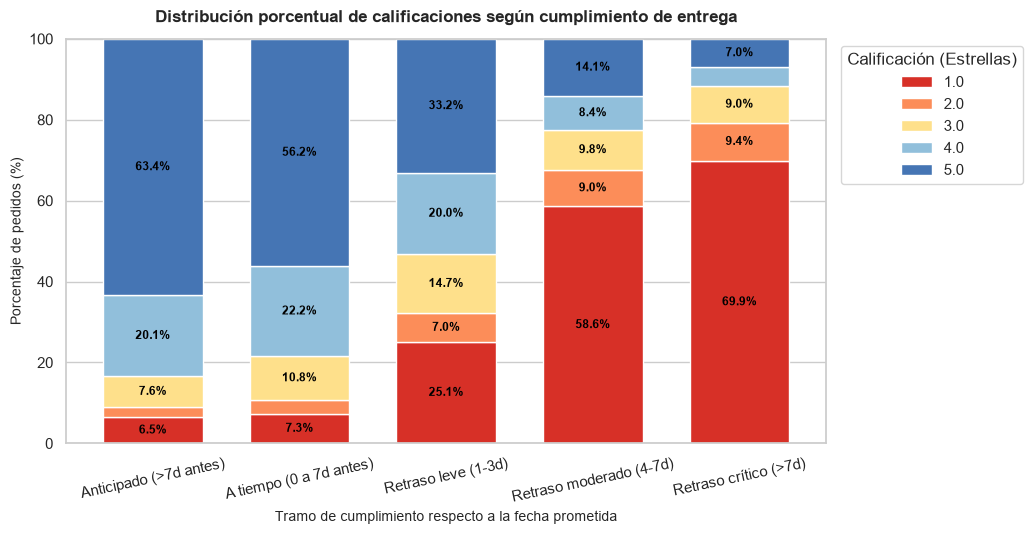

In [12]:
# Gráfico 1: Barras 100% apiladas de review_score por rango_cumplimiento
tabla_g1 = pd.crosstab(df_pedidos["rango_cumplimiento"], df_pedidos["review_score"], normalize="index") * 100

colores_estrellas = ["#d73027", "#fc8d59", "#fee08b", "#91bfdb", "#4575b4"]
ax = tabla_g1.plot(kind="bar", stacked=True, color=colores_estrellas, figsize=(10.5, 5.5), width=0.68)

for contenedor in ax.containers:
    etiquetas = [f"{v:.1f}%" if v >= 6 else "" for v in contenedor.datavalues]
    ax.bar_label(contenedor, labels=etiquetas, label_type="center", fontsize=8.5, color="black", fontweight="bold")

plt.title("Distribución porcentual de calificaciones según cumplimiento de entrega", fontsize=12, fontweight="bold", pad=12)
plt.xlabel("Tramo de cumplimiento respecto a la fecha prometida", fontsize=10)
plt.ylabel("Porcentaje de pedidos (%)", fontsize=10)
plt.xticks(rotation=12)
plt.ylim(0, 100)
plt.legend(title="Calificación (Estrellas)", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.savefig(FIGURES / "grafico_1_barras_retraso.png", dpi=300, bbox_inches="tight")
plt.show()

##Gráfica 1: Efecto umbral del incumplimiento en la fecha prometida

Podemos ver la composición porcentual de las calificaciones de 1 a 5 estrellas a lo largo de los cinco tramos operativos de entrega, normalizando cada columna al 100% para comparar proporciones independientemente del volumen de pedidos.
* Identificamos un **efecto umbral no lineal**, es decir, mientras el pedido llegue antes o dentro de la fecha prometida, las reseñas de 1 estrella se mantienen bajas (6.5% a 7.3%). Sin embargo, retrasarse de **1 a 3 días** triplica la proporción de 1 estrella (25.1%), y superar los **4 días de retraso** convierte a la calificación mínima en la respuesta mayoritaria (58.6% a 69.9%).

Puntualizando que nuestra variable `review_score` es ordinal y presenta un marcado **efecto techo** (59.2% de los pedidos reciben 5 estrellas), por lo que analizar proporciones por categoría aporta mayor precisión que comparar únicamente promedios.

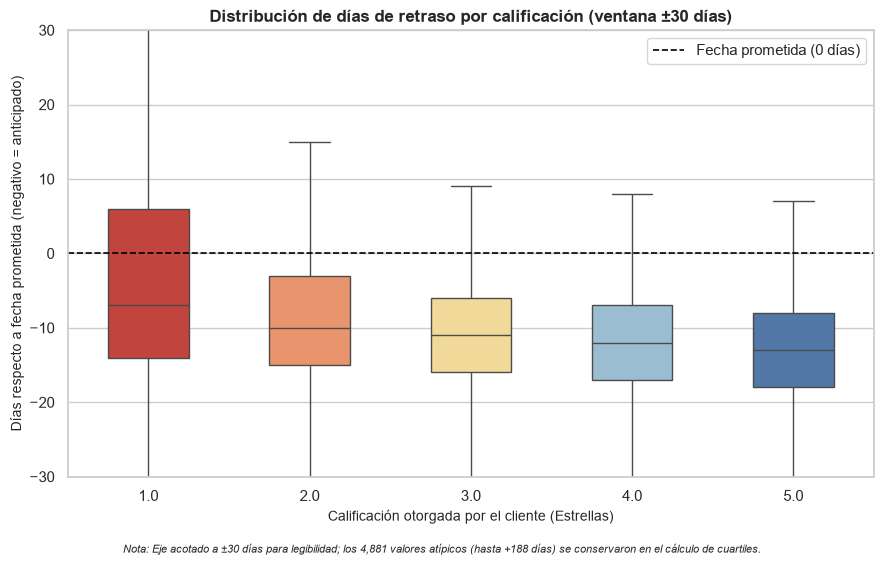

In [13]:
# Gráfico 2: Diagramas de caja (Boxplots) de días de retraso por calificación
plt.figure(figsize=(9, 5.5))

sns.boxplot(
    data=df_pedidos,
    x="review_score",
    y="retraso_dias",
    hue="review_score",
    palette=["#d73027", "#fc8d59", "#fee08b", "#91bfdb", "#4575b4"],
    legend=False,
    showfliers=False,
    width=0.5
)

plt.axhline(0, color="black", linestyle="--", linewidth=1.2, label="Fecha prometida (0 días)")

plt.title("Distribución de días de retraso por calificación (ventana ±30 días)", fontsize=12, fontweight="bold")
plt.xlabel("Calificación otorgada por el cliente (Estrellas)", fontsize=10)
plt.ylabel("Días respecto a fecha prometida (negativo = anticipado)", fontsize=10)
plt.ylim(-30, 30)
plt.legend(loc="upper right")
plt.figtext(
    0.5, -0.02,
    "Nota: Eje acotado a ±30 días para legibilidad; los 4,881 valores atípicos (hasta +188 días) se conservaron en el cálculo de cuartiles.",
    ha="center", fontsize=8, style="italic"
)
plt.tight_layout()
plt.savefig(FIGURES / "grafico_2_boxplot_retraso.png", dpi=300, bbox_inches="tight")
plt.show()

##Gráfico 2: Posición y dispersión del retraso según calificación

En esta gráfica podemos visualizar la mediana, los cuartiles ($Q_1, Q_3$) y la asimetría de los días de retraso para cada puntuación de 1 a 5 estrellas, destacando con una línea punteada el límite de cumplimiento ($0$ días).
* Identificamos que la insatisfacción no solo desplaza la mediana hacia el incumplimiento, sino que viene acompañada de un aumento drástico en la volatilidad logística. En 1 estrella, el rango intercuartílico se ensancha considerablemente y la caja cruza el umbral cero hacia demoras positivas, demostrando que la incertidumbre en la entrega deteriora severamente la evaluación.

Es importante mencionar que se recorta la ventana visual a $\pm 30$ días para evitar que las demoras extremas (de hasta +188 días) aplasten las cajas intercuartílicas, manteniendo todos los registros (incluidos los 4,881 atípicos) en el cálculo estadístico.

/var/folders/lb/529b_l255vd3v67byxkks8qm0000gn/T/ipykernel_44534/739167458.py:54: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/lb/529b_l255vd3v67byxkks8qm0000gn/T/ipykernel_44534/739167458.py:55: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  plt.savefig(FIGURES / "grafico_3_regiones_brasil.png", dpi=300, bbox_inches="tight")
/Users/gerardobalderas/Documents/VS CODE/MEMCD-Mod1-Proyecto/projmod1/lib/python3.15/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


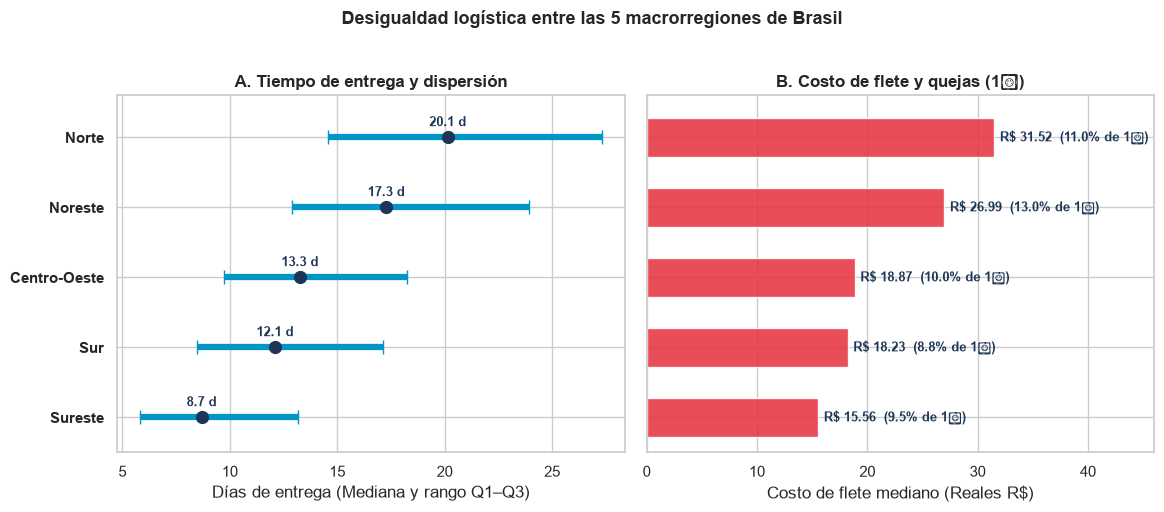

In [14]:
# Traducción de macrorregiones de portugués a español
traducir_region = {
    "Sudeste": "Sureste",
    "Sul": "Sur",
    "Centro-Oeste": "Centro-Oeste",
    "Nordeste": "Noreste",
    "Norte": "Norte"
}

resumen_reg = (
    df_pedidos.assign(region_es=df_pedidos["region"].replace(traducir_region))
    .groupby("region_es", as_index=False)
    .agg(
        mediana_entrega=("tiempo_entrega_dias", "median"),
        q1_entrega=("tiempo_entrega_dias", lambda s: s.quantile(0.25)),
        q3_entrega=("tiempo_entrega_dias", lambda s: s.quantile(0.75)),
        flete_mediano=("flete_total", "median"),
        pct_1_estrella=("review_score", lambda s: (s == 1).mean() * 100)
    )
    .sort_values("mediana_entrega")
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

y_pos = range(len(resumen_reg))
err_inf = resumen_reg["mediana_entrega"] - resumen_reg["q1_entrega"]
err_sup = resumen_reg["q3_entrega"] - resumen_reg["mediana_entrega"]

# Panel A: Tiempo de entrega y dispersión (Azul cobalto #1D3557 y turquesa #0096C7)
ax1.errorbar(
    resumen_reg["mediana_entrega"], y_pos,
    xerr=[err_inf, err_sup], fmt="o", color="#1D3557", ecolor="#0096C7", elinewidth=4.5, capsize=5, markersize=8.5
)
for i, val in enumerate(resumen_reg["mediana_entrega"]):
    ax1.text(val, i + 0.16, f"{val:.1f} d", ha="center", fontsize=9, fontweight="bold", color="#1D3557")
ax1.set_yticks(y_pos)
ax1.set_yticklabels(resumen_reg["region_es"], fontweight="bold")
ax1.set_ylim(-0.5, 4.6)  # Margen superior extra para que "20.1 d" no choque con el título
ax1.set_xlabel("Días de entrega (Mediana y rango Q1–Q3)")
ax1.set_title("A. Tiempo de entrega y dispersión", fontweight="bold")

# Panel B: Costo de flete y quejas (Rojo coral vibrante #E63946)
ax2.barh(y_pos, resumen_reg["flete_mediano"], color="#E63946", alpha=0.9, height=0.55)
for i, (flete, pct1) in enumerate(zip(resumen_reg["flete_mediano"], resumen_reg["pct_1_estrella"])):
    ax2.text(flete + 0.5, i, f"R$ {flete:.2f}  ({pct1:.1f}% de 1★)", va="center", fontsize=9, fontweight="bold", color="#1D3557")
ax2.set_yticks(y_pos)
ax2.set_yticklabels([])
ax2.set_ylim(-0.5, 4.6)
ax2.set_xlim(0, 46)
ax2.set_xlabel("Costo de flete mediano (Reales R$)")
ax2.set_title("B. Costo de flete y quejas (1★)", fontweight="bold")

plt.suptitle("Desigualdad logística entre las 5 macrorregiones de Brasil", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(FIGURES / "grafico_3_regiones_brasil.png", dpi=300, bbox_inches="tight")
plt.show()

##Gráfica 3: Desigualdad logística entre macrorregiones de Brasil

Podemos ver el contraste de la mediana y el rango intercuartílico ($Q_1\text{–}Q_3$) del tiempo total de entrega (Panel A) frente al costo de flete mediano y la proporción de calificaciones de 1 estrella (Panel B) en las cinco macrorregiones oficiales de Brasil.
* Econtramos la existencia de una brecha logística estructural. Un cliente en las regiones Norte y Noreste paga casi el doble de flete mediano (27.22 a 31.52 reales frente a 15.56 reales en Sureste), espera más del doble de tiempo (17.3 a 20.2 días frente a 8.7 días) y registra mayor proporción de reseñas de 1 estrella (11.9% a 13.0%).

Mencionando que la agregación por macrorregión oculta heterogeneidad interna entre capitales estatales con buena conectividad aérea y municipios rurales remotos del interior.

/Users/gerardobalderas/Documents/VS CODE/MEMCD-Mod1-Proyecto/projmod1/lib/python3.15/site-packages/seaborn/utils.py:61: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  fig.canvas.draw()
/var/folders/lb/529b_l255vd3v67byxkks8qm0000gn/T/ipykernel_44534/4058602754.py:56: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  plt.savefig(FIGURES / "grafico_4_split_y_correlacion.png", dpi=300, bbox_inches="tight")
/Users/gerardobalderas/Documents/VS CODE/MEMCD-Mod1-Proyecto/projmod1/lib/python3.15/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


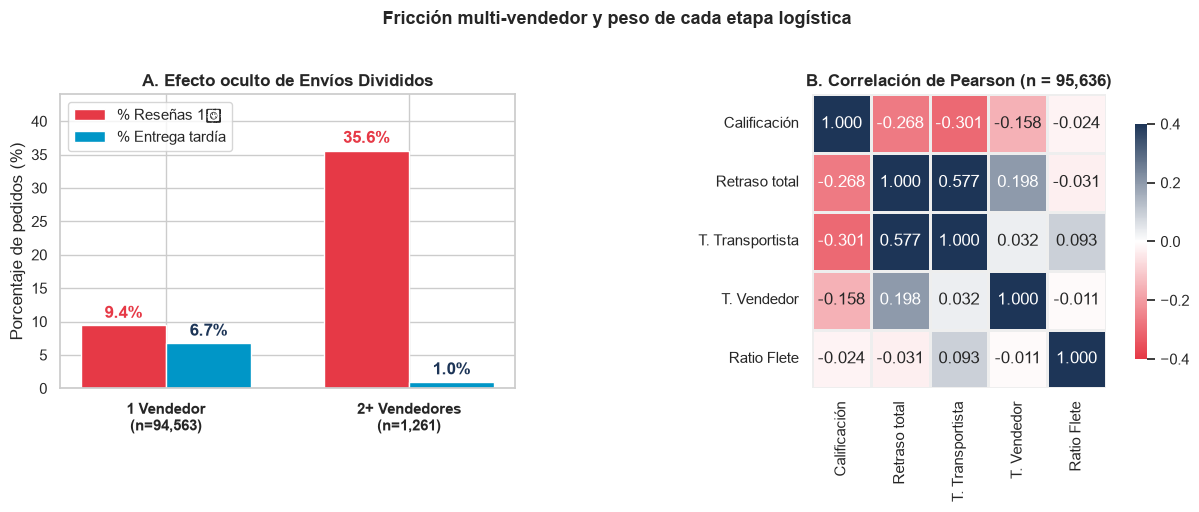

In [15]:
from matplotlib.colors import LinearSegmentedColormap

# Clasificar envíos divididos (Split Shipments)
df_pedidos["tipo_envio"] = np.where(
    df_pedidos["n_sellers"] == 1,
    "1 Vendedor\n(n=94,563)",
    "2+ Vendedores\n(n=1,261)"
)

resumen_sellers = (
    df_pedidos.groupby("tipo_envio", as_index=False)
    .agg(
        pct_1_estrella=("review_score", lambda s: (s == 1).mean() * 100),
        pct_tarde=("retraso_dias", lambda s: (s > 0).mean() * 100)
    )
)

# Filtrar las 188 anomalías cronológicas (Decisión 3) para correlaciones limpias
df_crono = df_pedidos[
    (df_pedidos["tiempo_vendedor_dias"] >= 0) &
    (df_pedidos["tiempo_transportista_dias"] >= 0)
].copy()

cols_corr = ["review_score", "retraso_dias", "tiempo_transportista_dias", "tiempo_vendedor_dias", "ratio_flete"]
nombres_corr = ["Calificación", "Retraso total", "T. Transportista", "T. Vendedor", "Ratio Flete"]
matriz_pearson = df_crono[cols_corr].corr(method="pearson")
matriz_pearson.index = nombres_corr
matriz_pearson.columns = nombres_corr

# Graficar ambos paneles con la paleta vibrante unificada
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 5), gridspec_kw={"width_ratios": [1, 1.3]})

x = np.arange(len(resumen_sellers))
ancho = 0.35
b1 = ax1.bar(x - ancho/2, resumen_sellers["pct_1_estrella"], width=ancho, label="% Reseñas 1★", color="#E63946")
b2 = ax1.bar(x + ancho/2, resumen_sellers["pct_tarde"], width=ancho, label="% Entrega tardía", color="#0096C7")

ax1.bar_label(b1, fmt="%.1f%%", padding=3, fontweight="bold", color="#E63946")
ax1.bar_label(b2, fmt="%.1f%%", padding=3, fontweight="bold", color="#1D3557")
ax1.set_xticks(x)
ax1.set_xticklabels(resumen_sellers["tipo_envio"], fontweight="bold")
ax1.set_ylim(0, 44)
ax1.set_ylabel("Porcentaje de pedidos (%)")
ax1.set_title("A. Efecto oculto de Envíos Divididos", fontweight="bold")
ax1.legend()

cmap_unificado = LinearSegmentedColormap.from_list("olist_vibrante", ["#E63946", "#FFFFFF", "#1D3557"])
sns.heatmap(
    matriz_pearson, annot=True, fmt=".3f", cmap=cmap_unificado, vmin=-0.4, vmax=0.4, center=0,
    square=True, linewidths=0.8, linecolor="#EEEEEE", ax=ax2, cbar_kws={"shrink": 0.8}
)
ax2.set_title("B. Correlación de Pearson (n = 95,636)", fontweight="bold")

plt.suptitle("Fricción multi-vendedor y peso de cada etapa logística", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(FIGURES / "grafico_4_split_y_correlacion.png", dpi=300, bbox_inches="tight")
plt.show()

##Gráfica 4: Envíos divididos y sensibilidad por etapa logística

El Panel A compara el porcentaje de reseñas de 1 estrella frente a la tasa de entrega tardía según el número de vendedores distintos por pedido. El Panel B muestra el mapa de calor de correlaciones de Pearson entre la calificación y los componentes de tiempo y flete ($n = 95,636$ pedidos tras filtrar anomalías cronológicas de pedidos donde el sistema registró que el paquete llegó al cliente antes de que el vendedor se lo entregara al transportista, dando tiempos negativos imposibles en la vida real).


* Se evidencian dos fenómenos clave: (1) En pedidos surtidos por 2 o más vendedores ($n = 1,261$), solo el 0.95% se entrega tarde, pero el 35.6% recibe 1 estrella, porque los paquetes se despachan por separado y el cliente evalúa negativamente al recibir solo una fracción inicial de su compra y (2) la demora del transportista ($r = -0.301$) impacta casi el doble en la insatisfacción que el tiempo de despacho del vendedor ($r = -0.158$).

Es importante recordar que las correlaciones bivariadas son moderadas y no prueban causalidad única, dado que la calificación del cliente también responde a factores no observados aquí como defectos del producto, daños en el empaque o entregas parciales.

# Conclusiones

A partir del análisis realizado, identificamos que el cumplimiento de los
tiempos de entrega, particularmente la etapa del transportista, y las
diferencias logísticas regionales representan áreas de oportunidad para
mejorar la experiencia y satisfacción de los clientes de Olist.

## Limitaciones del análisis

Los resultados corresponden a un análisis exploratorio. Las correlaciones
observadas son moderadas y no permiten establecer relaciones de causalidad,
ya que la satisfacción del cliente también puede depender de factores no
observados, como defectos del producto, daños en el empaque o entregas parciales.

Asimismo, el análisis se limitó a pedidos entregados y evaluados, lo que
puede generar un sesgo de selección y limitar la generalización de los
resultados al conjunto total de pedidos.

## Futuras líneas de investigación

- Implementar modelos multivariados, como la regresión logística ordinal,
  para analizar simultáneamente diferentes variables.
- Analizar los comentarios de las reseñas mediante técnicas de
  procesamiento de lenguaje natural.
- Incorporar información de geolocalización y vendedores para medir
  distancias e identificar oportunidades de mejora logística.
- Desarrollar modelos predictivos de retrasos y evaluar si las fechas
  estimadas de entrega son realistas.